### FunctionTransformer

`FunctionTransformer` is a Scikit-learn utility that converts a Python function into a transformer for ML preprocessing.

It allows us to apply `mathematical transformations` such as Log, Log1p, Square Root, and Reciprocal to features.

**Why use it?**
- Reduce skewness in data.
- Transform feature distributions.
- Apply custom functions during preprocessing.
- Integrate transformations with `Pipeline` and `ColumnTransformer`.

Example: `FunctionTransformer(np.log1p)` applies the transformation:

$$
X_{new} = \log(1 + X)
$$

#### When should you use FunctionTransformer?

Use `FunctionTransformer` when you want to apply a mathematical or custom function as part of a Scikit-learn preprocessing workflow.

**Good use cases**
- Reducing right-skewness with log or square-root transformations.
- Applying a domain-specific mathematical transformation.
- Applying the same transformation consistently during training and prediction.
- Applying a function to selected columns through `ColumnTransformer`.

**Advantages**
- Simple way to wrap NumPy or custom functions.
- Compatible with Scikit-learn transformers and pipelines.
- Makes preprocessing steps reusable and consistent.
- Can be combined with `ColumnTransformer` to target selected features.

**Limitations**
- It does not automatically decide which transformation is best.
- The function may have input restrictions, such as positive-only values for logarithms.
- A transformation may improve one feature or model but hurt another.
- It does not guarantee normally distributed data or better model performance.

In [1]:
import pandas as pd 
import numpy as np 

import scipy.stats as stats

import matplotlib.pyplot as plt 
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [2]:
df = pd.read_csv('Datasets/titanic.csv', usecols=['Age', 'Fare', 'Survived'])

In [3]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [4]:
df.isnull().sum()

Survived      0
Age         177
Fare          0
dtype: int64

In [5]:
# fill age missing value with the mean of the age 
df['Age'].fillna(df['Age'].mean(), inplace=True)

C:\Users\us\AppData\Local\Temp\ipykernel_14264\1839244139.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(df['Age'].mean(), inplace=True)


In [6]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [7]:
df.isnull().sum()

Survived    0
Age         0
Fare        0
dtype: int64

In [8]:
x = df.iloc[:, 1:3]
y = df.iloc[:, 0]

In [9]:
X_train, X_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42)

C:\Users\us\AppData\Local\Temp\ipykernel_14264\1340955907.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train['Age'])


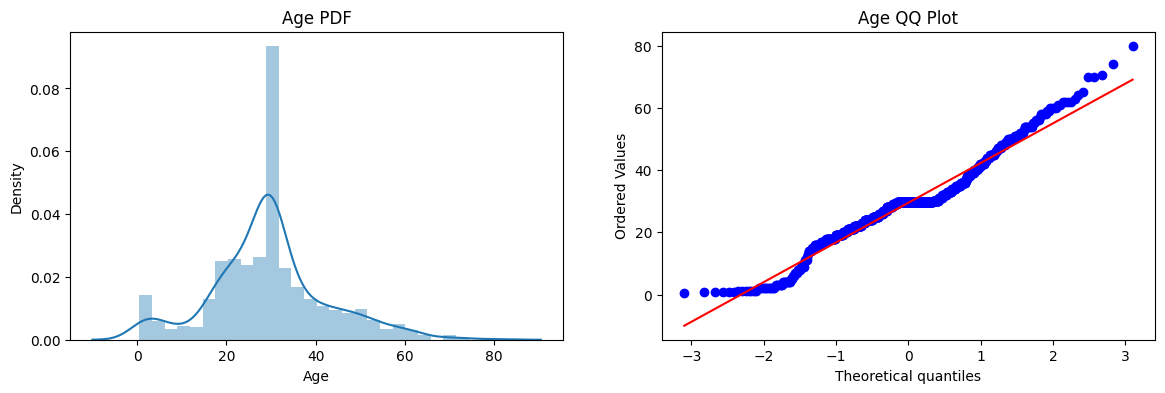

In [10]:
plt.figure(figsize=(14,4))

plt.subplot(121)
sns.distplot(X_train['Age'])
plt.title('Age PDF')

plt.subplot(122)
stats.probplot(X_train['Age'], dist='norm', plot=plt)
plt.title('Age QQ Plot')

plt.show();

C:\Users\us\AppData\Local\Temp\ipykernel_14264\2348892434.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train['Fare'])


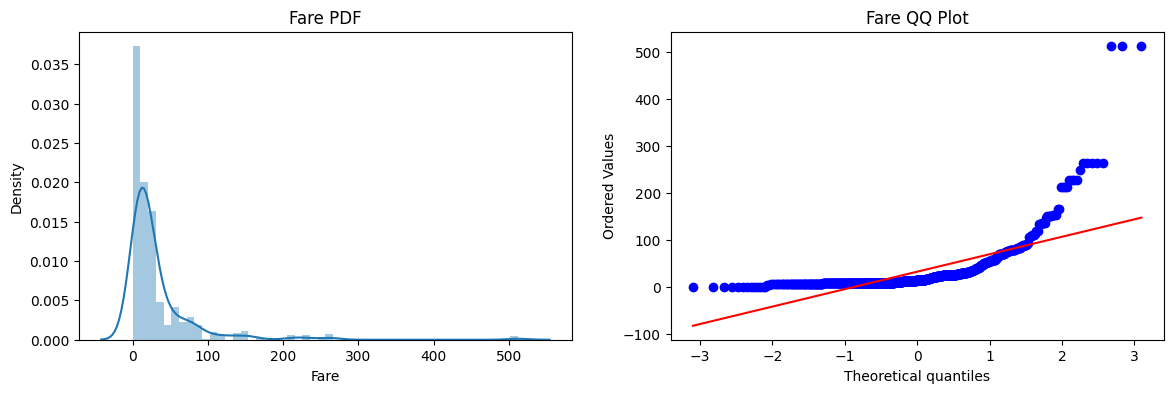

In [11]:
plt.figure(figsize=(14,4))

plt.subplot(121)
sns.distplot(X_train['Fare'])
plt.title('Fare PDF')

plt.subplot(122)
stats.probplot(X_train['Fare'], dist='norm', plot=plt)
plt.title('Fare QQ Plot')

plt.show();

In [12]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

In [13]:
clf.fit(X_train, y_train)
clf2.fit(X_train, y_train)

y_pred = clf.predict(X_test)
y_pred2 = clf2.predict(X_test)

print("------ Accuaracy Score without applying any transforms -------\n")
print(f'Accuaracy LR : {accuracy_score(y_test, y_pred)}')
print(f'Accuaracy DT : {accuracy_score(y_test, y_pred2)}')

------ Accuaracy Score without applying any transforms -------

Accuaracy LR : 0.6480446927374302
Accuaracy DT : 0.664804469273743


In [14]:
# CREATE OBJECT OF TRANSFORMER
trf = FunctionTransformer(func=np.log1p)

In [15]:
# Apply log transform of the both cols[age, fare]
X_train_transformed = trf.fit_transform(X_train)
X_test_transformed = trf.transform(X_test)

In [16]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

clf.fit(X_train_transformed, y_train)
clf2.fit(X_train_transformed, y_train)

y_pred = clf.predict(X_test_transformed)
y_pred2 = clf2.predict(X_test_transformed)

y_pred = clf.predict(X_test_transformed)
y_pred2 = clf2.predict(X_test_transformed)

print("Accuaracy Score after applying log transforms on both 'Age' And 'Fare' cols \n")

print(f'Accuaracy LR : {accuracy_score(y_test, y_pred)}')
print(f'Accuaracy DT : {accuracy_score(y_test, y_pred2)}')

Accuaracy Score after applying log transforms on both 'Age' And 'Fare' cols 

Accuaracy LR : 0.6815642458100558
Accuaracy DT : 0.6759776536312849


In [18]:
# check improvement using cross_val_score 
X_transformed = trf.fit_transform(x)

clf = LogisticRegression()
clf2 = DecisionTreeClassifier()


print("Cross Val Score after applying log transforms on both 'Age' And 'Fare' cols \n")

print(f'Cross Val Score of LR : {cross_val_score(clf, X_transformed, y, scoring='accuracy', cv=10).mean()}')
print(f'Cross Val Score of DT : {cross_val_score(clf2, X_transformed, y, scoring='accuracy', cv=10).mean()}')


Cross Val Score after applying log transforms on both 'Age' And 'Fare' cols 

Cross Val Score of LR : 0.678027465667915
Cross Val Score of DT : 0.6554931335830213


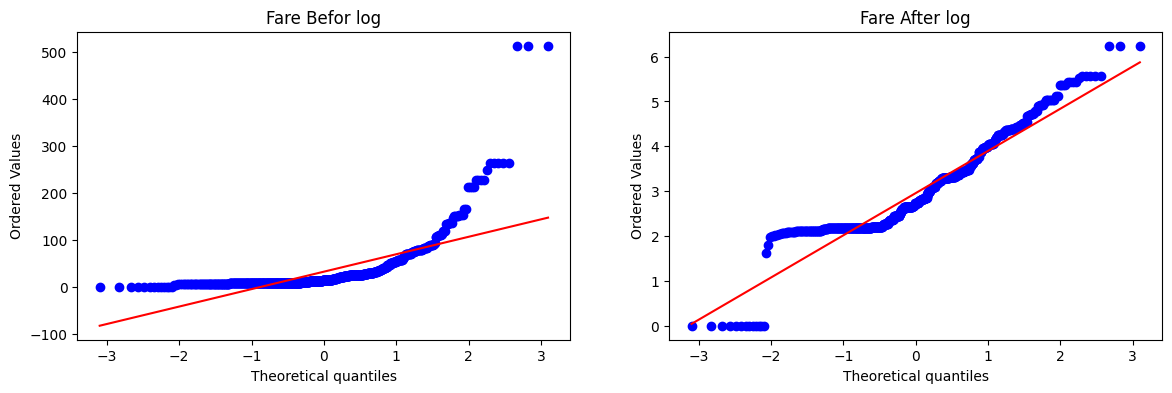

In [19]:
plt.figure(figsize=(14,4))

plt.subplot(121)
stats.probplot(X_train['Fare'], dist='norm', plot=plt)
plt.title('Fare Befor log')

plt.subplot(122)
stats.probplot(X_train_transformed['Fare'], dist='norm', plot=plt)
plt.title('Fare After log')

plt.show();

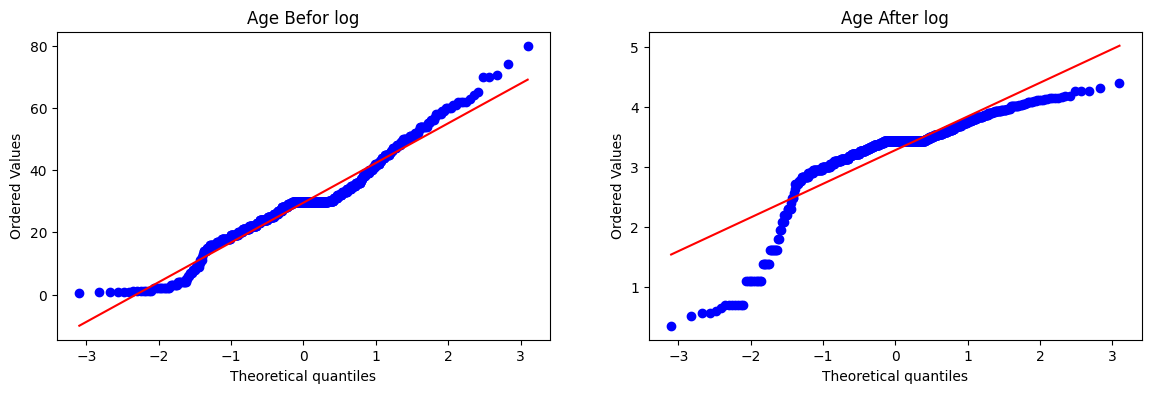

In [20]:
plt.figure(figsize=(14,4))

plt.subplot(121)
stats.probplot(X_train['Age'], dist='norm', plot=plt)
plt.title('Age Befor log')

plt.subplot(122)
stats.probplot(X_train_transformed['Age'], dist='norm', plot=plt)
plt.title('Age After log')

plt.show();    # here we see the after aplying log transformer in age cols , result are bad 

#### Applying a transformation to selected columns with ColumnTransformer

`FunctionTransformer` applies a function to the data passed to it. When only selected columns should be transformed, combine it with `ColumnTransformer`.

In this example:

- `FunctionTransformer(np.log1p)` applies the log1p transformation.
- `['Fare']` specifies that only the `Fare` column is transformed.
- `remainder='passthrough'` keeps all other columns unchanged.

This is useful when a dataset contains multiple numerical features but only some of them are skewed.

Conceptual flow:

```text
Input features
      |
      v
ColumnTransformer
      |
      +---- Fare ----> log1p transform
      |
      +---- Other columns ----> pass through unchanged
      |
      v
Combined transformed features
```

In [21]:
trf2 = ColumnTransformer([
    ('log', FunctionTransformer(np.log1p),['Fare'])
], remainder='passthrough')

In [22]:
trf2

ColumnTransformer(remainder='passthrough',
                  transformers=[('log',
                                 FunctionTransformer(func=<ufunc 'log1p'>),
                                 ['Fare'])])

In [23]:
X_train_transformed2 = trf2.fit_transform(X_train)
X_test_transformed2 = trf2.fit_transform(X_test)

In [24]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

In [25]:
clf.fit(X_train_transformed2, y_train)
clf2.fit(X_train_transformed2, y_train)

y_pred = clf.predict(X_test_transformed2)
y_pred2 = clf2.predict(X_test_transformed2)

y_pred = clf.predict(X_test_transformed2)
y_pred2 = clf2.predict(X_test_transformed2)

print("Accuaracy Score after applying log transforms Only 'Fare' col \n")

print(f'Accuaracy LR : {accuracy_score(y_test, y_pred)}')
print(f'Accuaracy DT : {accuracy_score(y_test, y_pred2)}')

Accuaracy Score after applying log transforms Only 'Fare' col 

Accuaracy LR : 0.6703910614525139
Accuaracy DT : 0.6703910614525139


### Experimenting with different transformation functions

The `apply_transform()` helper is intended to compare different mathematical transformations on the `Fare` feature.

The function argument `transforms` is intended to make the helper reusable for different functions. Check that the function is actually passed into `FunctionTransformer` when using the helper.

In [26]:
def apply_transform(transforms): 
    X = df.iloc[:, 1:3]
    y = df.iloc[:, 0]

    trf = ColumnTransformer([('log', FunctionTransformer(np.log1p),['Fare'])], remainder='passthrough')    

    X_trans = trf.fit_transform(X)

    clf = LogisticRegression()

    print("Accuracy score : ", np.mean(cross_val_score(clf, X_trans, y, scoring='accuracy', cv=10)))

    plt.figure(figsize=(14,4))

    plt.subplot(121)
    stats.probplot(X['Fare'], dist='norm', plot=plt)
    plt.title('Fare Befor transform')
    
    plt.subplot(122)
    stats.probplot(X_trans[:, 0], dist='norm', plot=plt)
    plt.title('Fare After transform')
    
    plt.show();
    

#### Log1p transformation experiment

`np.log1p` is suitable when values can include zero and are non-negative. It compresses large values while preserving their order.

Accuracy score :  0.6712609238451936


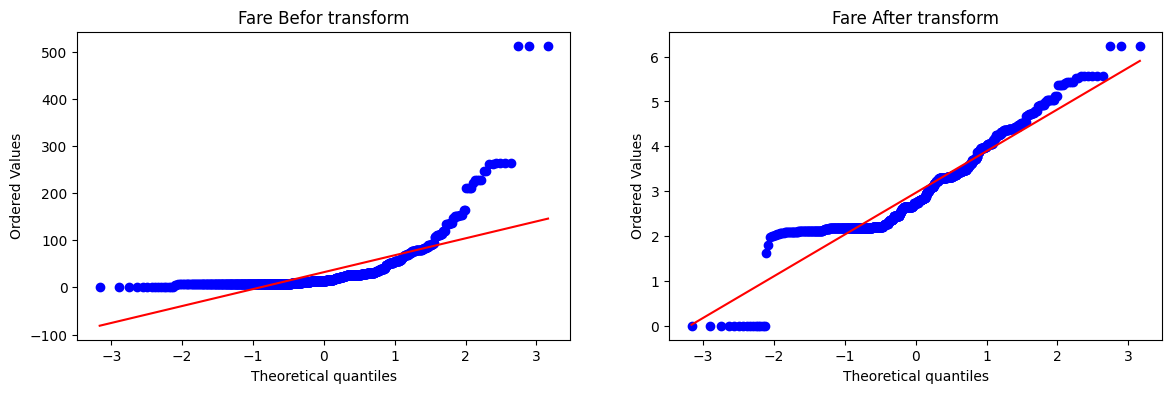

In [27]:
apply_transform(np.log1p)

#### Reciprocal Transformation Experiment

The reciprocal transformation is:

\[
y = \frac{1}{x}
\]

It can substantially change the relationship between values. It cannot be applied when a value is zero, and it may be difficult to interpret after transformation.

Accuracy score :  0.6712609238451936


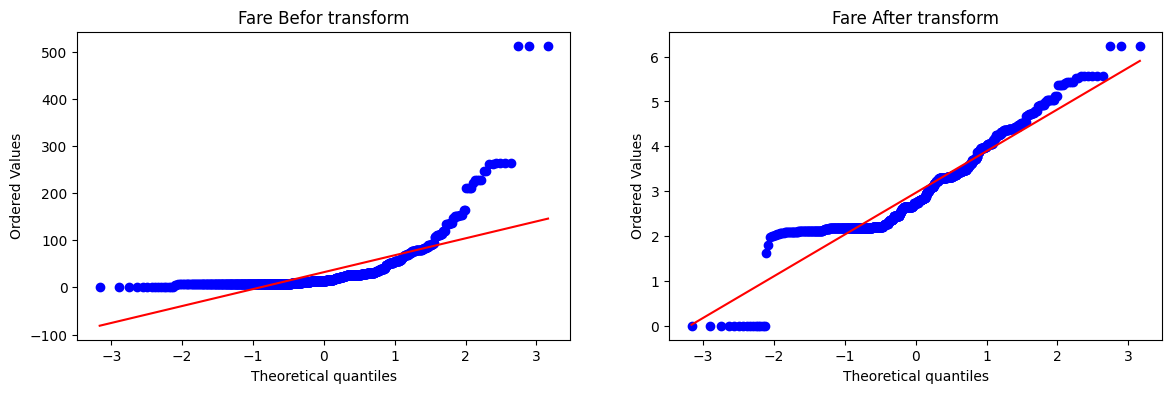

In [28]:
# Reciprocal Transformer
apply_transform(lambda x : 1/x)

#### Square-root Transformation Experiment

The square-root transformation is:

\[
y = \sqrt{x}
\]

It reduces the spread of larger non-negative values. It is generally a milder compression than a logarithmic transformation.

Accuracy score :  0.6712609238451936


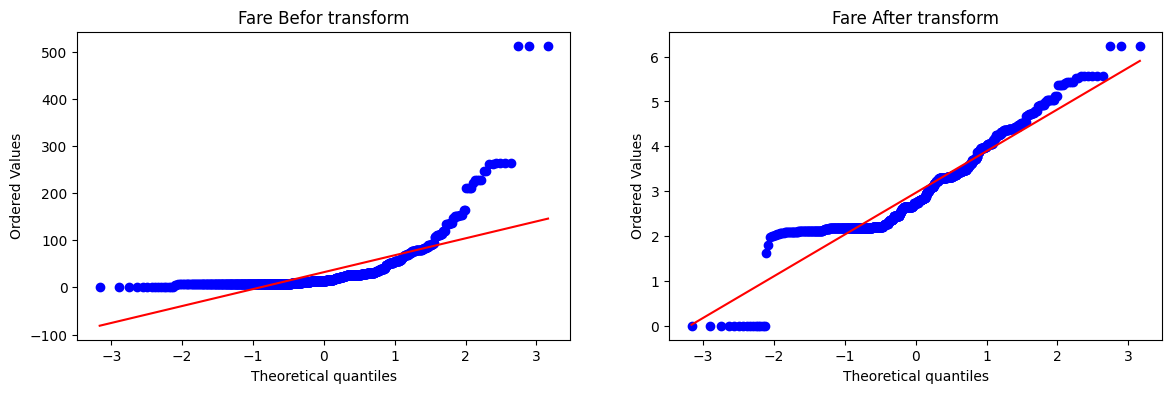

In [29]:
apply_transform(lambda x: np.sqrt(x))

#### Natural Logarithm Experiment

The natural logarithm transformation is:

\[
y = \log(x)
\]

It requires strictly positive values. If a feature contains zeros, consider `np.log1p` instead, provided all values are greater than or equal to zero.

Accuracy score :  0.6712609238451936


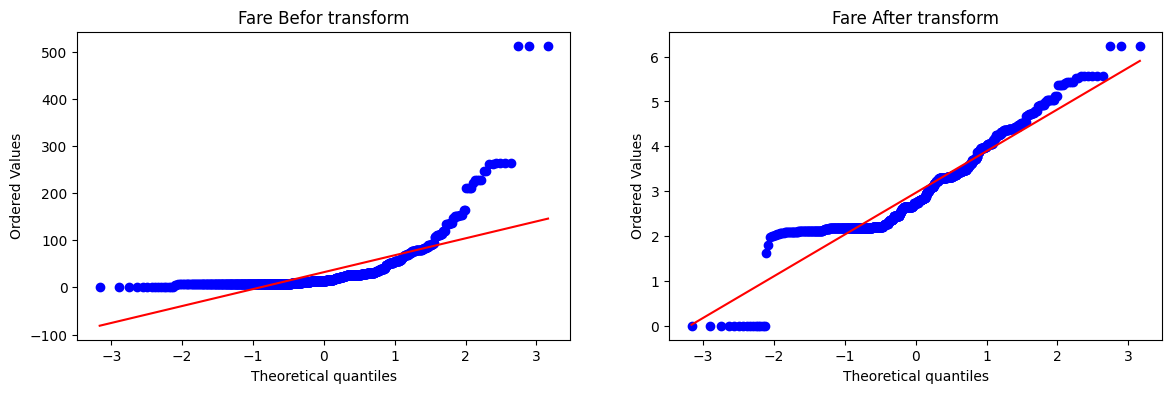

In [30]:
apply_transform(np.log)

### Key takeaways

1. `FunctionTransformer` wraps a Python function so it can be used in Scikit-learn preprocessing.
2. `np.log1p(x)` computes `log(1 + x)` and can handle zero values.
3. Use `ColumnTransformer` when only selected columns should be transformed.
4. Different features can benefit from different transformations.
5. Always check input constraints and validate the effect on model performance.